In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib
import zipfile
import urllib.request
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "spam_dataset.zip")

with zipfile.ZipFile("spam_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("spam_data")

df = pd.read_csv(
    "spam_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset downloaded successfully!")
print(df.head())


Dataset downloaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
print(df["label"].value_counts())


Dataset Shape: (5572, 2)

Missing Values:
label      0
message    0
dtype: int64

Category Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["message"] = df["message"].apply(clean_text)

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df.dropna(inplace=True)

print("Text preprocessing completed!")
print(df.head())


Text preprocessing completed!
   label                                            message
0      0  go until jurong point crazy available only in ...
1      0                            ok lar joking wif u oni
2      1  free entry in a wkly comp to win fa cup final ...
3      0        u dun say so early hor u c already then say
4      0  nah i dont think he goes to usf he lives aroun...


In [14]:

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)


TF-IDF conversion completed!
Training matrix: (4457, 5000)
Testing matrix: (1115, 5000)


In [15]:

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training samples: 4457
Testing samples: 1115


In [16]:

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Trained Successfully!")



Logistic Regression Model Trained Successfully!


In [17]:

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))


MODEL EVALUATION RESULTS
------------------------
Accuracy: 96.5 %
Precision: 1.0
Recall: 0.7383
F1 Score: 0.8494

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.97      0.96      1115



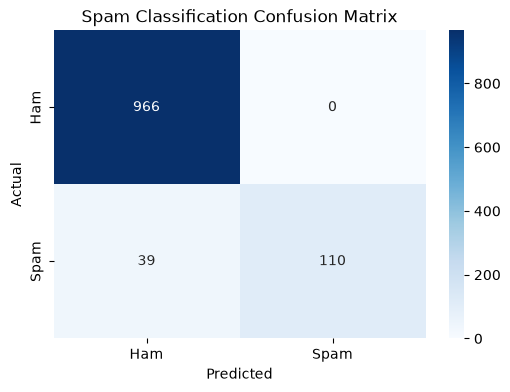

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Spam Classification Confusion Matrix")

plt.show()


In [19]:
joblib.dump(
    {
        "model": model,
        "tfidf": tfidf
    },
    "spam_classifier_model.pkl"
)

print("Model exported successfully!")


Model exported successfully!


In [20]:
def predict_spam(message):

    cleaned_message = clean_text(message)

    message_tfidf = tfidf.transform([cleaned_message])

    prediction = model.predict(message_tfidf)

    if prediction[0] == 1:
        return "SPAM"
    else:
        return "HAM"

# Test messages

test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting today?",
    "URGENT! You have won a cash reward. Call now!",
    "Please send me the assignment notes."
]

for message in test_messages:

    result = predict_spam(message)

    print("Message:", message)
    print("Prediction:", result)
    print("------------------------------")


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
------------------------------
Message: Hey, are we meeting today?
Prediction: HAM
------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
------------------------------
Message: Please send me the assignment notes.
Prediction: HAM
------------------------------


In [21]:
loaded_data = joblib.load("spam_classifier_model.pkl")

loaded_model = loaded_data["model"]
loaded_tfidf = loaded_data["tfidf"]

print("Saved model loaded successfully!")

sample = ["Congratulations! You won a free gift"]

sample_vector = loaded_tfidf.transform(sample)

result = loaded_model.predict(sample_vector)

print("Final Prediction:",
      "SPAM" if result[0] == 1 else "HAM")


Saved model loaded successfully!
Final Prediction: SPAM


In [4]:
# Email Spam Classifier – Model Evaluation

In [5]:

# Install required libraries if needed
%pip install -q pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:

# Standard library imports
import re
import zipfile
import logging
from pathlib import Path

# Third-party imports
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

# Configuration
RANDOM_STATE = 42
TEST_SIZE = 0.20
MODEL_PATH = Path("spam_classifier_model.pkl")
DATA_DIR = Path("spam_data")
DATASET_PATH = DATA_DIR / "SMSSpamCollection"
REPORT_PATH = Path("spam_evaluation_report.md")

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)
logger = logging.getLogger(__name__)

print("All libraries imported successfully.")


All libraries imported successfully.


In [2]:

def load_trained_model(model_path):
    """Load the trained classifier and TF-IDF vectorizer."""
    if not model_path.exists():
        raise FileNotFoundError(
            f"Model file not found: {model_path.resolve()}. "
            "Place your trained model in the notebook folder."
        )

    saved_objects = joblib.load(model_path)

    if not isinstance(saved_objects, dict):
        raise ValueError("Expected a dictionary containing model and tfidf.")

    required_keys = {"model", "tfidf"}
    missing_keys = required_keys.difference(saved_objects)

    if missing_keys:
        raise KeyError(f"Missing model components: {missing_keys}")

    model = saved_objects["model"]
    vectorizer = saved_objects["tfidf"]

    if not hasattr(model, "predict"):
        raise TypeError("Loaded model does not support prediction.")

    if not hasattr(vectorizer, "transform"):
        raise TypeError("Loaded vectorizer does not support transformation.")

    logger.info("Trained model and TF-IDF vectorizer loaded successfully.")
    return model, vectorizer


model, tfidf = load_trained_model(MODEL_PATH)

print("Model:", type(model).__name__)
print("Vectorizer:", type(tfidf).__name__)


INFO: Trained model and TF-IDF vectorizer loaded successfully.


Model: LogisticRegression
Vectorizer: TfidfVectorizer


In [3]:

def load_dataset(dataset_path):
    """Load the SMS Spam Collection dataset."""
    if not dataset_path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {dataset_path.resolve()}. "
            "Extract SMSSpamCollection into the spam_data folder."
        )

    data = pd.read_csv(
        dataset_path,
        sep="\t",
        header=None,
        names=["label", "message"],
        usecols=[0, 1],
        encoding="latin-1"
    )

    data = data.dropna(subset=["label", "message"])
    data["label"] = data["label"].str.strip().str.lower()

    data = data[data["label"].isin(["ham", "spam"])].copy()
    data["target"] = data["label"].map({"ham": 0, "spam": 1})

    if data.empty or data["target"].nunique() != 2:
        raise ValueError("Dataset must contain both ham and spam messages.")

    logger.info("Dataset loaded: %d messages", len(data))
    return data


def preprocess_text(text):
    """Normalize SMS text using the project's preprocessing approach."""
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


data = load_dataset(DATASET_PATH)

data["clean_message"] = data["message"].apply(preprocess_text)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    data["clean_message"],
    data["target"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=data["target"]
)

# Use the already-trained vectorizer. Never fit it again here.
X_test = tfidf.transform(X_test_text)

print("Dataset shape:", data.shape)
print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))
print("Test feature shape:", X_test.shape)
print("\nTest class distribution:")
print(y_test.value_counts())


INFO: Dataset loaded: 5572 messages


Dataset shape: (5572, 4)
Training samples: 4457
Testing samples: 1115
Test feature shape: (1115, 5000)

Test class distribution:
target
0    966
1    149
Name: count, dtype: int64


In [4]:

def evaluate_model(model, X_test, y_test):
    """Calculate classification metrics and generate predictions."""
    predictions = model.predict(X_test)

    metrics = {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ),
        "classification_report": classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            zero_division=0
        )
    }

    logger.info("Model evaluation completed.")
    return predictions, metrics


y_pred, metrics = evaluate_model(model, X_test, y_test)

print("=" * 50)
print("CLASSIFICATION EVALUATION RESULTS")
print("=" * 50)

print(f"Accuracy  : {metrics['accuracy']:.4f}")
print(f"Precision : {metrics['precision']:.4f}")
print(f"Recall    : {metrics['recall']:.4f}")
print(f"F1-Score  : {metrics['f1_score']:.4f}")

print("\nClassification Report:")
print(metrics["classification_report"])


INFO: Model evaluation completed.


CLASSIFICATION EVALUATION RESULTS
Accuracy  : 0.9641
Precision : 1.0000
Recall    : 0.7315
F1-Score  : 0.8450

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.73      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.97      0.96      0.96      1115



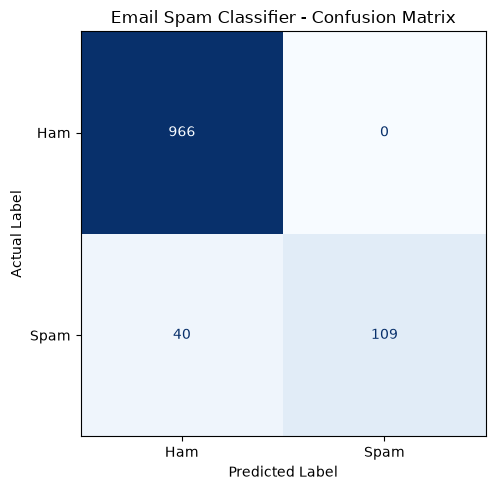

In [5]:

def plot_confusion_matrix(matrix):
    """Visualize the confusion matrix."""
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Ham", "Spam"]
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    display.plot(
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title("Email Spam Classifier - Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(metrics["confusion_matrix"])


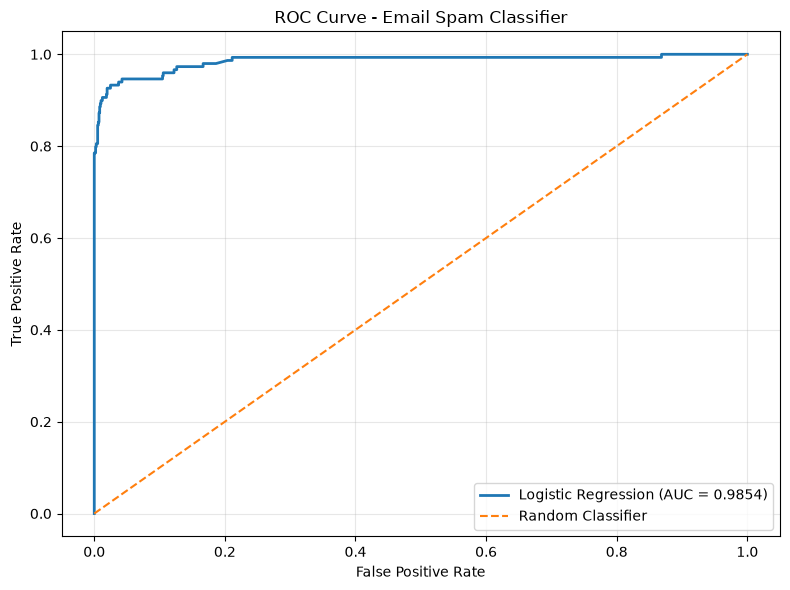

ROC-AUC Score: 0.9854


In [6]:

def plot_roc_curve(model, X_test, y_test):
    """Plot the ROC curve and calculate AUC."""
    if not hasattr(model, "predict_proba"):
        raise TypeError(
            "The classifier must support predict_proba for ROC evaluation."
        )

    probabilities = model.predict_proba(X_test)[:, 1]

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(y_test, probabilities)

    plt.figure(figsize=(8, 6))

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"Logistic Regression (AUC = {auc_score:.4f})"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve - Email Spam Classifier")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

    return auc_score


auc_score = plot_roc_curve(model, X_test, y_test)

print(f"ROC-AUC Score: {auc_score:.4f}")


In [7]:

def generate_evaluation_report(metrics, auc_score, report_path):
    """Create a detailed Markdown evaluation report."""

    matrix = metrics["confusion_matrix"]

    tn, fp, fn, tp = matrix.ravel()

    report = f"""# Email Spam Classifier - Evaluation Report

## 1. Project Overview

The project uses a Logistic Regression classifier with TF-IDF
feature extraction to identify spam and legitimate SMS messages.

## 2. Model Configuration

- Algorithm: Logistic Regression
- Feature extraction: TF-IDF
- Maximum TF-IDF features: 5000
- Test size: 20%
- Random state: 42

## 3. Evaluation Results

| Metric | Score |
|---|---:|
| Accuracy | {metrics['accuracy']:.4f} |
| Precision | {metrics['precision']:.4f} |
| Recall | {metrics['recall']:.4f} |
| F1-Score | {metrics['f1_score']:.4f} |
| ROC-AUC | {auc_score:.4f} |

## 4. Confusion Matrix

| Actual / Predicted | Ham | Spam |
|---|---:|---:|
| Ham | {tn} | {fp} |
| Spam | {fn} | {tp} |

## 5. Classification Report

```text
{metrics['classification_report']}
```

## 6. Analysis

The classifier was evaluated using accuracy, precision,
recall, F1-score, confusion matrix, and ROC-AUC.

Precision indicates the reliability of spam predictions.
Recall measures the ability to identify actual spam messages.
The F1-score balances precision and recall.

## 7. Possible Improvements

1. Experiment with different TF-IDF configurations.
2. Compare Logistic Regression with Multinomial Naive Bayes.
3. Apply hyperparameter tuning using cross-validation.
4. Handle class imbalance using appropriate techniques.
5. Test the model on new and unseen SMS messages.
6. Experiment with n-grams and feature selection.
7. Monitor false positives and false negatives.

## 8. Conclusion

The evaluation provides a quantitative assessment of the
trained spam classification model. The results can be used
to identify strengths and areas requiring improvement.
"""

    report_path.write_text(report, encoding="utf-8")

    logger.info("Evaluation report saved to %s", report_path.resolve())


generate_evaluation_report(metrics, auc_score, REPORT_PATH)

print("Markdown evaluation report generated successfully.")
print("Report location:", REPORT_PATH.resolve())


INFO: Evaluation report saved to C:\Users\pghat\spam_evaluation_report.md


Markdown evaluation report generated successfully.
Report location: C:\Users\pghat\spam_evaluation_report.md


In [9]:
## Possible Improvements

In [10]:

def verify_project_outputs():
    """Verify that all required evaluation files exist."""

    required_files = [
        Path("spam_classifier_model.pkl"),
        Path("confusion_matrix.png"),
        Path("roc_curve.png"),
        REPORT_PATH
    ]

    print("=" * 50)
    print("PROJECT OUTPUT VERIFICATION")
    print("=" * 50)

    all_valid = True

    for file_path in required_files:
        exists = file_path.exists()
        status = "PASS" if exists else "MISSING"

        print(f"{status}: {file_path}")

        if not exists:
            all_valid = False

    if all_valid:
        print("\nAll required project files are available.")
    else:
        print("\nSome files are missing. Check the earlier cells.")

    return all_valid


project_verified = verify_project_outputs()


PROJECT OUTPUT VERIFICATION
PASS: spam_classifier_model.pkl
PASS: confusion_matrix.png
PASS: roc_curve.png
PASS: spam_evaluation_report.md

All required project files are available.


In [11]:

def predict_message(message, model, vectorizer):
    """Predict whether a new message is spam or ham."""

    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please provide a non-empty message.")

    cleaned_message = preprocess_text(message)
    transformed_message = vectorizer.transform([cleaned_message])

    prediction = int(model.predict(transformed_message)[0])

    label = "SPAM" if prediction == 1 else "HAM"

    return label


sample_message = "Congratulations! You have won a free prize. Call now!"

result = predict_message(sample_message, model, tfidf)

print("Sample message:", sample_message)
print("Prediction:", result)


Sample message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
